[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/helvecioneto/datascience/blob/main/praticas/pratica03-3-redes-neurais.ipynb)

# Aula Prática 03 · Exemplo 3 de 3: Redes Neurais

**Disciplina:** Introdução à Ciência de Dados (NSA A110) · **Professor:** Helvecio Bezerra Leal Neto · UFOPA
**Data:** 29/10/2026, 19h às 22h · **Modalidade:** prática em equipes (2 a 3 pessoas)

Hoje são **três notebooks curtos**, um para cada técnica: **1.** clusterização com DBSCAN · **2.** árvore de decisão · **3.** redes neurais. Este é o **3**.

### Como usar este notebook
Leia cada bloco de texto **antes** de rodar a célula de código logo abaixo dele. Os ícones dizem o que fazer:

| Ícone | O que você faz |
|---|---|
| ▶️ **Rode** | A célula está pronta. Execute com `Shift + Enter` e leia a saída. |
| 🧭 **Complete** | Troque cada `___` pelo que o texto pede e rode. Se travar, abra o **💡 Ver resposta** logo abaixo, mas tente antes. |
| ✍️ **Responda** | Escreva a resposta da equipe na célula de texto indicada (dois cliques para editar). |

Rode as células **na ordem**, de cima para baixo. Se algo der errado: *Ambiente de execução → Reiniciar e executar tudo*.

### Objetivos
Ao final, a equipe será capaz de:
- **Explicar** como um neurônio artificial decide: entradas × pesos, soma e ativação.
- **Treinar** uma rede neural que reconhece dígitos escritos à mão e **acompanhar** o treino pela curva de erro.
- **Avaliar** a rede (acurácia, matriz de confusão, erros) e **comparar** com a árvore de decisão.

### O problema: ler números escritos à mão

Os Correios leem o **CEP** escrito à mão em milhões de cartas; os bancos leem o valor escrito nos cheques. Ninguém digita isso: um **modelo** olha a imagem e diz qual é o dígito.

Vamos construir um leitor desses. Os dados são **1 797 imagens** pequenas de dígitos (0 a 9) escritos à mão por pessoas de verdade. A base já vem **dentro do scikit-learn** (não precisa baixar nada). Para cada imagem sabemos qual dígito é: é o **rótulo**. Então é **aprendizado supervisionado**, de classificação, agora com **10 classes**.

A técnica de hoje é a **rede neural**, a mesma família de modelos por trás do reconhecimento de voz, dos carros autônomos e dos **grandes modelos de linguagem** (como o ChatGPT) da Aula 04. A nossa vai ser bem pequena, mas o princípio é o mesmo.

## Etapa 0 · Preparar o ambiente
▶️ **Rode.**

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")   # esconde avisos técnicos do treino que não importam hoje
SEMENTE = 42                        # mesma semente = mesmos resultados para todas as equipes
print("Tudo pronto!")

Tudo pronto!


## Etapa 1 · Conhecer os dados
▶️ **Rode** para carregar as imagens e ver as 10 primeiras, com o rótulo de cada uma.

Imagens: 1797
Tamanho de cada imagem: (8, 8) pixels


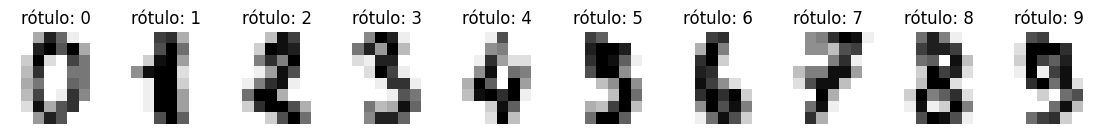

In [2]:
digitos = load_digits()
print("Imagens:", len(digitos.images))
print("Tamanho de cada imagem:", digitos.images[0].shape, "pixels")

fig, eixos = plt.subplots(1, 10, figsize=(14, 2))
for i, ax in enumerate(eixos):
    ax.imshow(digitos.images[i], cmap="gray_r")
    ax.set_title(f"rótulo: {digitos.target[i]}")
    ax.axis("off")
plt.show()

### Para o computador, uma imagem é uma tabela de números
Cada imagem tem **8 × 8 pixels**, e cada pixel é um número de **0** a **16**, que diz o quanto ele está pintado.

🧭 **Complete:** escolham o número de uma imagem (de 0 a 1796) e vejam a mesma imagem como **números** e como **figura**.

Rótulo (o dígito verdadeiro): 1
[[ 0  0  0 12 13  5  0  0]
 [ 0  0  0 11 16  9  0  0]
 [ 0  0  3 15 16  6  0  0]
 [ 0  7 15 16 16  2  0  0]
 [ 0  0  1 16 16  3  0  0]
 [ 0  0  1 16 16  6  0  0]
 [ 0  0  1 16 16  6  0  0]
 [ 0  0  0 11 16 10  0  0]]


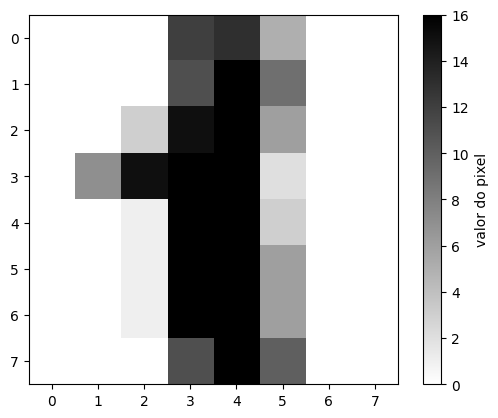

In [8]:
N = 1   # número da imagem escolhida pela equipe (de 0 a 1796)

print("Rótulo (o dígito verdadeiro):", digitos.target[N])
print(digitos.images[N].astype(int))

plt.imshow(digitos.images[N], cmap="gray_r")
plt.colorbar(label="valor do pixel")
plt.show()

<details>
<summary>💡 <b>Ver resposta</b> (tente antes!)</summary>

```python
N = 7   # qualquer número de 0 a 1796 serve
```
</details>

✍️ **Responda:**
1. Comparem a tabela de números com a figura. O que quer dizer um pixel **0**? E um pixel **16**?
2. Quantos números, no total, descrevem uma imagem?

**✍️ Respostas da equipe**

1. 0 = branco, 16 = preto; espectro cinza de maior ou menor "tinta" para formar um numero
2. 64

Para o modelo, cada imagem vira **uma linha com 64 colunas** (as 8 linhas da imagem, uma depois da outra). É o mesmo formato de sempre: uma tabela **X** e um rótulo **y**.

▶️ **Rode.**

In [9]:
print("Tabela X:", digitos.data.shape, "→ (imagens, pixels)")
print("Rótulos y:", digitos.target[:20], "...")

Tabela X: (1797, 64) → (imagens, pixels)
Rótulos y: [0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5 6 7 8 9] ...


## Etapa 2 · O que é um neurônio artificial?
Antes da rede, uma peça só: o **neurônio**. Ele é uma **conta simples** que toma uma decisão de sim ou não. Exemplo: **vou à praia hoje?**

| Entrada | Valor | **Peso** (a importância dela) |
|---|---|---|
| Está fazendo sol? | 1 = sim, 0 = não | **+2** |
| É dia de folga? | 1 = sim, 0 = não | **+3** |
| A previsão diz chuva? | 1 = sim, 0 = não | **-4** (peso negativo: puxa para "não") |

O neurônio faz três coisas:
1. multiplica cada **entrada** pelo seu **peso**;
2. **soma** tudo e acrescenta um número fixo, o **viés** (aqui, **-2.5**: é a "preguiça" de sair de casa);
3. **ativação**: se a soma for **maior que zero**, a resposta é **sim**.

🧭 **Complete** a última linha com uma combinação de entradas inventada pela equipe (cada uma 0 ou 1) e rodem.

In [11]:
def neuronio(sol, folga, chuva):
    soma = 2 * sol + 3 * folga + (-4) * chuva + (-2.5)    # entradas × pesos, mais o viés
    decisao = "vai à praia" if soma > 0 else "fica em casa"
    print(f"sol={sol}, folga={folga}, chuva={chuva}  →  soma = {soma:+.1f}  →  {decisao}")

neuronio(1, 1, 0)
neuronio(1, 0, 0)
neuronio(1, 1, 1)

sol=1, folga=1, chuva=0  →  soma = +2.5  →  vai à praia
sol=1, folga=0, chuva=0  →  soma = -0.5  →  fica em casa
sol=1, folga=1, chuva=1  →  soma = -1.5  →  fica em casa
sol=1, folga=1, chuva=0  →  soma = +2.5  →  vai à praia
sol=1, folga=0, chuva=0  →  soma = -0.5  →  fica em casa
sol=1, folga=1, chuva=1  →  soma = -1.5  →  fica em casa


<details>
<summary>💡 <b>Ver resposta</b> (tente antes!)</summary>

```python
neuronio(1, 1, 1)   # sol e folga, mas com chuva prevista
```
</details>

✍️ **Responda:**
1. Com sol e folga, mas **chuva prevista**, a pessoa vai? Façam a conta.
2. **Palpite:** aqui, **nós** escolhemos os pesos. Quem vocês acham que escolhe os pesos numa rede neural? (A resposta está no próximo texto: confiram depois.)

**✍️ Respostas da equipe**

1. 2(1)+3(1)−4(1)−2,5=−1,5
Resposta: não vai à praia; fica em casa, pois a soma é menor que zero.

2. Os pesos são ajustados automaticamente durante o treinamento da rede neural, usando os dados de treino e comparando as previsões com as respostas corretas.

### De um neurônio para uma rede
Uma **rede neural** é feita de muitos neurônios como esse, organizados em **camadas**. A do meio se chama **camada oculta** porque fica escondida entre a entrada e a saída: não vemos diretamente o que ela calcula.

```
  64 pixels        ──►   camada oculta    ──►   camada de saída
  (a imagem)             32 neurônios           10 neurônios: um para cada dígito (0, 1, …, 9)
```

- Cada neurônio da **camada oculta** faz a mesma conta da praia, só que com **64 entradas** (os pixels) e 64 pesos. Cada um costuma aprender a reagir a algo como um **pedaço de traço** (uma curva, uma linha reta…).
- Uma diferença em relação à praia: na rede, a ativação não responde só "sim" ou "não". Se a soma for **negativa**, o neurônio passa **0** adiante; se for **positiva**, passa **o próprio valor** (o quanto ela é positiva).
- Cada neurônio da **saída** junta o que a camada oculta viu e diz *"o quanto isto parece um 0, um 1, …"*. Os 10 valores viram **probabilidades** que somam 100%, e a resposta da rede é o dígito com a **maior** probabilidade.
- **Treinar** é ajustar todos esses pesos ao mesmo tempo, em várias **rodadas** (chamadas **épocas**), errando um pouco menos a cada uma.

## Etapa 3 · Preparar os dados
Dois cuidados, ▶️ já prontos na célula:
1. **Escala:** os pixels vão de 0 a 16; dividimos por 16 para ficarem entre **0 e 1**. Redes neurais aprendem melhor com números pequenos.
2. **Treino e teste** (75% / 25%), como sempre: a nota final é dada com imagens que a rede **nunca viu**.

▶️ **Rode.**

In [13]:
X = digitos.data / 16     # pixels de 0 a 16 viram números de 0 a 1
y = digitos.target

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEMENTE   # stratify=y: mesma proporção de cada dígito no treino e no teste
)
print("Treino:", X_treino.shape[0], "imagens")
print("Teste: ", X_teste.shape[0], "imagens")

Treino: 1347 imagens
Teste:  450 imagens


## Etapa 4 · Treinar a rede neural
No scikit-learn, a rede neural se chama `MLPClassifier` (*Multi-Layer Perceptron*, ou "perceptron de várias camadas"). Os parâmetros:
- `hidden_layer_sizes=(32,)`: **uma** camada oculta com **32** neurônios;
- `max_iter=500`: no máximo 500 **épocas** de treino.

E o gesto é o mesmo da árvore: `modelo.fit(X, y)`.

🧭 **Complete** com as imagens e os rótulos **de treino**. O treino leva poucos segundos.

In [15]:
rede = MLPClassifier(hidden_layer_sizes=(32,), max_iter=500, random_state=SEMENTE)
rede.fit(X_treino, y_treino)


print("Treino concluído em", rede.n_iter_, "épocas")   # para antes de 500 quando o erro deixa de melhorar
n_pesos = sum(p.size for p in rede.coefs_) + sum(b.size for b in rede.intercepts_)   # conta tudo (não precisa entender esta linha)
print("Quantidade de pesos e vieses que a rede ajustou:", n_pesos)


Treino concluído em 398 épocas
Quantidade de pesos e vieses que a rede ajustou: 2410


<details>
<summary>💡 <b>Ver resposta</b> (tente antes!)</summary>

```python
rede.fit(X_treino, y_treino)
```
</details>

### Acompanhando o aprendizado
A cada época a rede mede o **erro** que está cometendo no treino, chamado de **perda**. A perda **não é uma porcentagem**: é uma nota de *"quão longe a rede está das respostas certas"*. O valor exato não importa; importa que ela **diminua** (zero seria perfeito).

▶️ **Rode** para ver como ela muda.

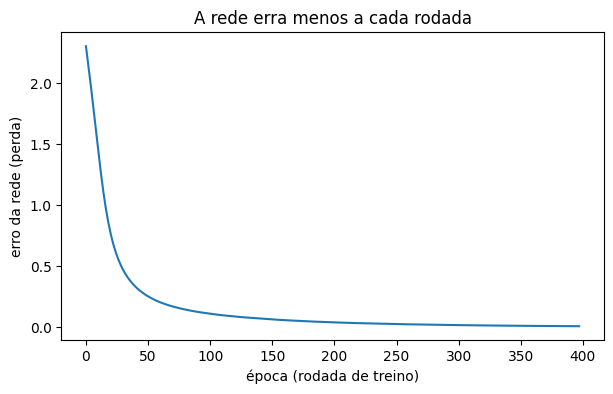

In [16]:
plt.figure(figsize=(7, 4))
plt.plot(rede.loss_curve_)
plt.xlabel("época (rodada de treino)")
plt.ylabel("erro da rede (perda)")
plt.title("A rede erra menos a cada rodada")
plt.show()

✍️ **Responda:**
1. Quantos pesos e vieses a rede ajustou? Comparem com os **3 pesos e 1 viés** do neurônio da praia.
2. Descrevam a curva: o erro cai rápido ou devagar no começo? E no final?

**✍️ Respostas da equipe**

1. A rede ajustou 2.410 pesos e vieses no total, enquanto o neurônio da praia tinha apenas 4 parâmetros: 3 pesos e 1 viés. Portanto, a rede neural ajusta muito mais parâmetros para aprender a reconhecer os dígitos


2. No começo: o erro cai , mostrando que a rede está aprendendo a cada rodada

No final: o erro diminui mais devagar e se aproxima de zero, indicando que a rede está refinando o que aprendeu




## Etapa 5 · Avaliar no teste
🧭 **Complete** com o método que **faz previsões** (*prever*, em inglês; é o mesmo que vocês usaram com a árvore no notebook 2).

Linha de base, para comparar: com 10 dígitos quase igualmente frequentes, o modelo preguiçoso que **chuta sempre o dígito mais comum** acerta só uns **10%**.

In [17]:
previsoes = rede.predict(X_teste)

print(f"Acurácia da rede neural:            {accuracy_score(y_teste, previsoes):.1%}")
print(f"Linha de base (sempre o mais comum): {np.bincount(y_teste).max() / len(y_teste):.1%}")   # bincount conta quantas vezes aparece cada dígito

Acurácia da rede neural:            97.6%
Linha de base (sempre o mais comum): 10.2%


<details>
<summary>💡 <b>Ver resposta</b> (tente antes!)</summary>

```python
previsoes = rede.predict(X_teste)
```
</details>

A **matriz de confusão** agora é 10 × 10: **linhas** = dígito verdadeiro, **colunas** = o que a rede respondeu. Tudo na **diagonal** é acerto; fora dela, confusões.

▶️ **Rode.**

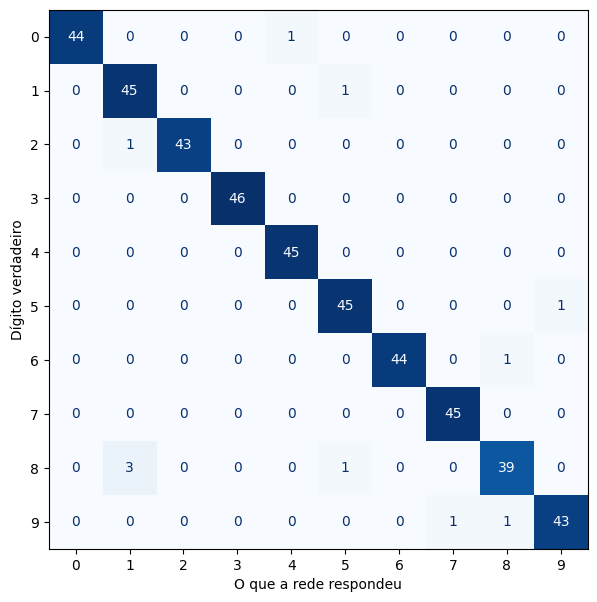

In [18]:
fig, ax = plt.subplots(figsize=(7, 7))
ConfusionMatrixDisplay.from_predictions(y_teste, previsoes, cmap="Blues", colorbar=False, ax=ax)
ax.set_xlabel("O que a rede respondeu")
ax.set_ylabel("Dígito verdadeiro")
plt.show()

✍️ **Responda:** procurem os números **fora da diagonal** (lembrem: a **linha** é o dígito verdadeiro e a **coluna** é o que a rede respondeu). Qual confusão aparece mais vezes? Faz sentido, pelo formato dos dígitos? *(Na Etapa 6 vocês vão ver essas imagens.)*

**✍️ Resposta da equipe:** a rede confundiu o número 8 com o 1 em 3 imagens




### O que a rede "pensa" sobre uma imagem
Lembram dos **10 neurônios de saída**? O `predict_proba` mostra o que cada um disse, como uma **probabilidade**. No gráfico, cada barra é um neurônio de saída: quanto mais alta, mais a rede aposta naquele dígito. Uma rede **segura** dá uma barra perto de 1,0 e as outras perto de 0.

▶️ **Rode** com `i = 0` e respondam a pergunta abaixo. **Depois** troquem o `i` por outros números (de 0 a 449) e rodem de novo, para comparar.

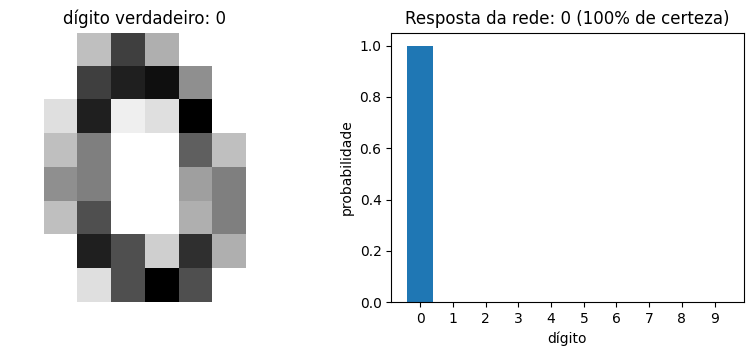

In [28]:
i = 1     # número da imagem de teste

prob = rede.predict_proba(X_teste[i:i + 1])[0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.imshow(X_teste[i].reshape(8, 8), cmap="gray_r")
ax1.set_title(f"dígito verdadeiro: {y_teste[i]}")
ax1.axis("off")
ax2.bar(range(10), prob, color="tab:blue")
ax2.set_xticks(range(10))
ax2.set_xlabel("dígito")
ax2.set_ylabel("probabilidade")
ax2.set_title(f"Resposta da rede: {prob.argmax()} ({prob.max():.0%} de certeza)")
plt.show()

✍️ **Responda:** na imagem `i = 0`, a rede acertou? Ela estava **segura**? Que outros dígitos ela considerou? Comparem com `i = 1`.

**✍️ Resposta da equipe:** com i=0 ela indicou o 1 com mais probabilidade o numero, e com 5,6,8 com menos probabilidade. i= 1 ela acertou com sem erros


## Etapa 6 · Onde a rede errou?
▶️ **Rode** para ver **todas** as imagens de teste em que a rede errou, com a resposta verdadeira e a da rede.

A rede errou 11 de 450 imagens de teste


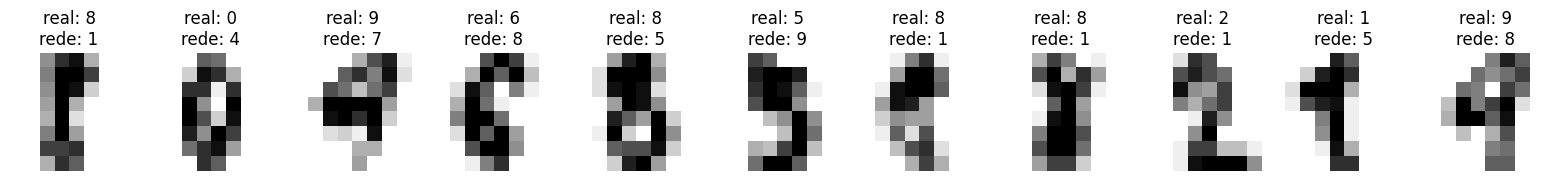

In [29]:
erradas = np.where(previsoes != y_teste)[0]
print(f"A rede errou {len(erradas)} de {len(y_teste)} imagens de teste")

fig, eixos = plt.subplots(1, len(erradas), figsize=(1.8 * len(erradas), 2.4), squeeze=False)
for ax, i in zip(eixos[0], erradas):
    ax.imshow(X_teste[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"real: {y_teste[i]}\nrede: {previsoes[i]}")
    ax.axis("off")
plt.show()

✍️ **Responda:** olhando as imagens, vocês teriam acertado todas? Escolham **uma** em que a rede errou e expliquem por que ela pode ter se confundido.

**✍️ Resposta da equipe:** nao, o 6 com o 8 sao parecidos, por isso a rede errou


## Etapa 7 · O tamanho da rede importa?
E se a camada oculta tivesse **menos** ou **mais** neurônios? ▶️ **Rode** para treinar redes com 1, 2, 5, 10, 32 e 100 neurônios (leva alguns segundos).

⏱️ *Se o tempo estiver curto, apenas rodem, olhem o gráfico e sigam para a Etapa 8.*

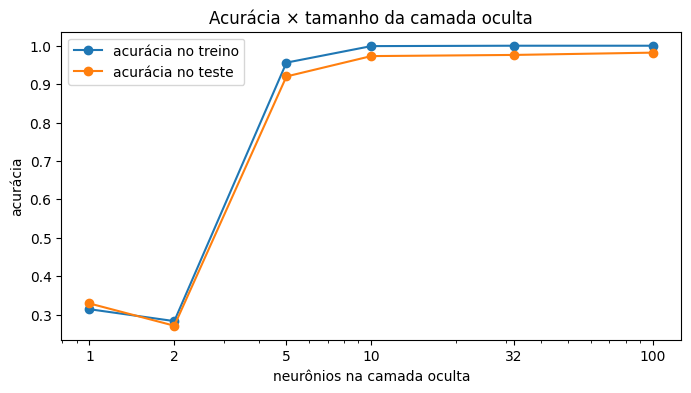

,neurônios na camada oculta,acurácia no treino,acurácia no teste
0,1,0.314,0.329
1,2,0.283,0.271
2,5,0.956,0.920
3,10,0.999,0.973
4,32,1.000,0.976
5,100,1.000,0.982


In [30]:
tabela = []
for n in [1, 2, 5, 10, 32, 100]:
    r = MLPClassifier(hidden_layer_sizes=(n,), max_iter=500, random_state=SEMENTE).fit(X_treino, y_treino)
    tabela.append({"neurônios na camada oculta": n,
                   "acurácia no treino": accuracy_score(y_treino, r.predict(X_treino)),
                   "acurácia no teste": accuracy_score(y_teste, r.predict(X_teste))})
tabela = pd.DataFrame(tabela).round(3)

ax = tabela.plot(x="neurônios na camada oculta", y=["acurácia no treino", "acurácia no teste"],
                 marker="o", logx=True, figsize=(8, 4))
ax.set_xticks([1, 2, 5, 10, 32, 100], [1, 2, 5, 10, 32, 100])   # escreve os números de neurônios no eixo
ax.set_ylabel("acurácia")
ax.set_title("Acurácia × tamanho da camada oculta")
plt.show()
tabela

✍️ **Responda:**
1. O que acontece com **1 ou 2** neurônios? Por que vocês acham que é tão ruim? *(Dica: cada neurônio oculto reage a um pedaço de traço. Dá para separar 10 dígitos olhando só 1 ou 2 traços?)*
2. A partir de quantos neurônios a rede fica boa? Vale a pena passar de 32 para 100?

**✍️ Respostas da equipe**

1. porque existem poucos neurônios para identificar os dígitos, nao funciona bem
2. 5 aumenta de 0.28 para 0.95. nao a ganhos significativos de 32 para 100, mas seria ainda mais preciso

## Etapa 8 · Rede neural × árvore de decisão
No notebook 2 a árvore foi ótima com o Titanic. E com imagens?

🧭 **Complete:** treinem uma **árvore de decisão** nos **mesmos** dados de treino da rede.

In [31]:
arvore = DecisionTreeClassifier(random_state=SEMENTE)
arvore.fit(X_treino, y_treino)


print(f"Árvore de decisão: {accuracy_score(y_teste, arvore.predict(X_teste)):.1%}")
print(f"Rede neural:       {accuracy_score(y_teste, previsoes):.1%}")

Árvore de decisão: 82.4%
Rede neural:       97.6%


<details>
<summary>💡 <b>Ver resposta</b> (tente antes!)</summary>

```python
arvore.fit(X_treino, y_treino)
```
</details>

✍️ **Responda:**
1. Qual modelo foi melhor com as imagens? Por quanto?
2. Por que a rede vai melhor aqui? *(Dica: a árvore pergunta sobre **um pixel por vez**; cada neurônio da rede olha **os 64 pixels ao mesmo tempo**.)*
3. Então por que não usar sempre redes neurais? *(Dica: no notebook 2 vocês leram as regras da árvore, como "se é homem e tem mais de 9 anos, então…". Dá para ler regras assim nos 2 410 pesos da rede?)*

**✍️ Respostas da equipe**

1. rede neural, 15,2 %
2. porque cada neuronio analisa ao mesmo tempo, e com mais detalhes. diferente da arvore de decisao
3. redes neurais podem oferecer maior precisão, mas sao mais dificeis de explicar, enquanto árvores de decisão geralmente são mais fáceis de interpretar e explicar

## 🏁 Desafio extra (para quem terminar antes)
**Desenhem o próprio dígito!** A tabela abaixo é um **7** desenhado "à mão" com números de 0 a 16. Rodem e vejam o que a rede responde. Depois **editem os números** para desenhar outro dígito (um 1, um 0, um 4…) e testem de novo. A rede acerta o desenho de vocês?

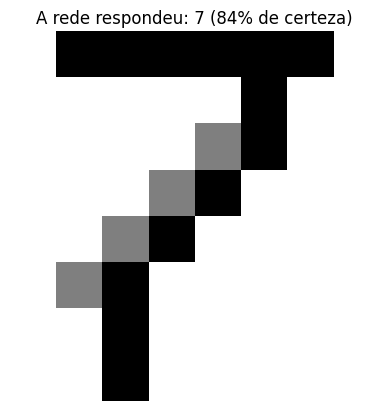

In [34]:
meu_digito = np.array([
    [0, 16, 16, 16, 16, 16, 16, 0],
    [0,  0,  0,  0,  0, 16,  0, 0],
    [0,  0,  0,  0,  8, 16,  0, 0],
    [0,  0,  0,  8, 16,  0,  0, 0],
    [0,  0,  8, 16,  0,  0,  0, 0],
    [0,  8, 16,  0,  0,  0,  0, 0],
    [0,  0, 16,  0,  0,  0,  0, 0],
    [0,  0, 16,  0,  0,  0,  0, 0],
])


prob = rede.predict_proba(meu_digito.reshape(1, -1) / 16)[0]   # mesma escala do treino: dividir por 16
plt.imshow(meu_digito, cmap="gray_r")
plt.title(f"A rede respondeu: {prob.argmax()} ({prob.max():.0%} de certeza)")
plt.axis("off")
plt.show()

**✍️ Resposta da equipe:** sim, acertou o 7 com 84% de certeza


## Encerramento
**O que fizemos:**
1. Vimos que uma imagem, para o computador, é uma **tabela de números** (64 pixels).
2. Entendemos o **neurônio**: entradas × pesos, soma com viés e ativação.
3. Treinamos uma **rede neural** com 32 neurônios e vimos o erro cair a cada **época**.
4. A rede acertou **≈ 98%** dos dígitos, contra 10% da linha de base e ≈ 82% da árvore.
5. Vimos que o **tamanho** da rede importa e que redes são ótimas com imagens, mas são **caixas-pretas**.

**Os três exemplos de hoje, juntos:**

| Notebook | Técnica | Tipo | Para quê |
|---|---|---|---|
| 1 | DBSCAN | não supervisionado | achar grupos (e ruído) sem rótulo |
| 2 | Árvore de decisão | supervisionado | prever com regras que dá para ler |
| 3 | Rede neural | supervisionado | prever com dados complexos, como imagens |